# Genetic evidence vs research attention for Parkinson's disease targets


## Step 1 · Setup

In [ ]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 20)
plt.rcParams["figure.dpi"] = 110

DISEASE_ID = "MONDO_0005180"   # Parkinson disease in Open Targets
FOCUS_GENE = "GBA1"            # change this to look at a different gene
print("Ready")

Ready


## Step 2 · Download Open Targets associations
This asks the Open Targets API for every target associated with Parkinson's disease, with its **overall score** and its score for each **evidence type** (genetic association, literature, known drugs, animal models, etc.). Scores run from 0 to 1.

*If the API fails*, download the "Associated targets" table from platform.opentargets.org/disease/MONDO_0005180/associations as a TSV, upload it in the Files panel on the left, and set `USE_FILE = True`.

In [ ]:
USE_FILE = False
OT_FILE = "associations.tsv"   # only used if USE_FILE = True

query = '''
query($id: String!, $index: Int!, $size: Int!) {
  disease(efoId: $id) {
    name
    associatedTargets(page: {index: $index, size: $size}) {
      count
      rows {
        target { approvedSymbol approvedName }
        score
        datatypeScores { id score }
      }
    }
  }
}'''

def fetch_open_targets(disease_id, max_rows=1000, page_size=500):
    url = "https://api.platform.opentargets.org/api/v4/graphql"
    rows, index = [], 0
    while len(rows) < max_rows:
        r = requests.post(url, json={"query": query,
                                     "variables": {"id": disease_id, "index": index, "size": page_size}},
                          timeout=60)
        r.raise_for_status()
        block = r.json()["data"]["disease"]["associatedTargets"]
        for row in block["rows"]:
            rec = {"gene": row["target"]["approvedSymbol"],
                   "name": row["target"]["approvedName"],
                   "overall": row["score"]}
            for d in row["datatypeScores"]:
                rec[d["id"]] = d["score"]
            rows.append(rec)
        index += 1
        if index * page_size >= block["count"]:
            break
    return pd.DataFrame(rows)

if USE_FILE:
    ot = pd.read_csv(OT_FILE, sep="\t")
    print("Loaded from file — check the column names below and rename them to match the API version if needed")
else:
    ot = fetch_open_targets(DISEASE_ID)

ot = ot.fillna(0)
ot.to_csv("open_targets_parkinsons.csv", index=False)   # keep a copy of the raw data
print(f"{len(ot)} targets downloaded")
ot.head(10)

1000 targets downloaded


,gene,name,overall,genetic_literature,affected_pathway,literature,genetic_association,animal_model,rna_expression,clinical,somatic_mutation
0,LRRK2,leucine rich repeat kinase 2,0.878971,0.862917,0.55547,0.998684,0.926534,0.263052,0.000000,0.000000,0.0
1,ATP13A2,ATPase cation transporting 13A2,0.871460,0.887274,0.00000,0.865471,0.936194,0.349256,0.000000,0.000000,0.0
2,SNCA,synuclein alpha,0.870636,0.914481,0.00000,0.997373,0.922776,0.000000,0.035571,0.490586,0.0
3,PRKN,parkin RBR E3 ubiquitin protein ligase,0.851986,0.811091,0.00000,0.992591,0.942978,0.428725,0.000000,0.000000,0.0
4,PINK1,PTEN induced kinase 1,0.850835,0.836521,0.00000,0.984625,0.940941,0.334210,0.000000,0.000000,0.0
5,PLA2G6,phospholipase A2 group VI,0.827075,0.897872,0.00000,0.929272,0.882480,0.563971,0.000000,0.000000,0.0
6,DNAJC6,DnaJ heat shock protein family (Hsp40) member C6,0.819517,0.928268,0.00000,0.828289,0.826134,0.000000,0.025659,0.000000,0.0
7,PARK7,Parkinsonism associated deglycase,0.810820,0.797134,0.00000,0.984552,0.897147,0.252291,0.000000,0.000000,0.0
8,FBXO7,F-box protein 7,0.800521,0.846915,0.00000,0.824033,0.878938,0.000000,0.000000,0.000000,0.0
9,VPS35,VPS35 retromer complex component,0.784813,0.853481,0.00000,0.959825,0.743579,0.000000,0.000000,0.000000,0.0


### Check the data
Good practice: check a couple of numbers by hand against the website before trusting them. Look up two genes from the table below on platform.opentargets.org and note in the AI log whether the scores match.

In [ ]:
print("Columns:", list(ot.columns))
print("Missing values per column:\n", ot.isna().sum())
ot[ot["gene"].isin([FOCUS_GENE, "LRRK2", "SNCA"])]

Columns: ['gene', 'name', 'overall', 'genetic_literature', 'affected_pathway', 'literature', 'genetic_association', 'animal_model', 'rna_expression', 'clinical', 'somatic_mutation']
Missing values per column:
 gene                   0
name                   0
overall                0
genetic_literature     0
affected_pathway       0
literature             0
genetic_association    0
animal_model           0
rna_expression         0
clinical               0
somatic_mutation       0
dtype: int64


,gene,name,overall,genetic_literature,affected_pathway,literature,genetic_association,animal_model,rna_expression,clinical,somatic_mutation
0,LRRK2,leucine rich repeat kinase 2,0.878971,0.862917,0.55547,0.998684,0.926534,0.263052,0.000000,0.000000,0.0
2,SNCA,synuclein alpha,0.870636,0.914481,0.00000,0.997373,0.922776,0.000000,0.035571,0.490586,0.0
10,GBA1,glucosylceramidase beta 1,0.774035,0.547138,0.00000,0.997114,0.894516,0.000000,0.000000,0.000000,0.0


## Step 3 · Load the GWAS Catalog data
1. Go to **ebi.ac.uk/gwas**, search **Parkinson disease**, open the trait page and download the associations as a TSV.
2. Run the cell below and choose that file when the upload button appears.

The code looks for the chromosome, position, p-value, gene and odds-ratio columns automatically, because the Catalog's column names vary between download formats.

In [ ]:
try:
    from google.colab import files
    uploaded = files.upload()
    GWAS_FILE = list(uploaded.keys())[0]
except ImportError:
    GWAS_FILE = "gwas_parkinsons.tsv"   # if running outside Colab, put the file name here

gwas_raw = pd.read_csv(GWAS_FILE, sep="\t", low_memory=False)
print(gwas_raw.shape)
print(list(gwas_raw.columns))

Saving gwas-association-downloaded_2026-10-19-MONDO_0005180.tsv to gwas-association-downloaded_2026-10-19-MONDO_0005180.tsv
(905, 38)
['DATE ADDED TO CATALOG', 'PUBMEDID', 'FIRST AUTHOR', 'DATE', 'JOURNAL', 'LINK', 'STUDY', 'DISEASE/TRAIT', 'INITIAL SAMPLE SIZE', 'REPLICATION SAMPLE SIZE', 'REGION', 'CHR_ID', 'CHR_POS', 'REPORTED GENE(S)', 'MAPPED_GENE', 'UPSTREAM_GENE_ID', 'DOWNSTREAM_GENE_ID', 'SNP_GENE_IDS', 'UPSTREAM_GENE_DISTANCE', 'DOWNSTREAM_GENE_DISTANCE', 'STRONGEST SNP-RISK ALLELE', 'SNPS', 'MERGED', 'SNP_ID_CURRENT', 'CONTEXT', 'INTERGENIC', 'RISK ALLELE FREQUENCY', 'P-VALUE', 'PVALUE_MLOG', 'P-VALUE (TEXT)', 'OR or BETA', '95% CI (TEXT)', 'PLATFORM [SNPS PASSING QC]', 'CNV', 'MAPPED_TRAIT', 'MAPPED_TRAIT_URI', 'STUDY ACCESSION', 'GENOTYPING TECHNOLOGY']


In [ ]:
def find_col(df, options):
    lower = {c.lower(): c for c in df.columns}
    for o in options:
        if o.lower() in lower:
            return lower[o.lower()]
    return None

cols = {
    "chr":  find_col(gwas_raw, ["CHR_ID", "chromosome", "chr"]),
    "pos":  find_col(gwas_raw, ["CHR_POS", "base_pair_location", "position", "pos"]),
    "p":    find_col(gwas_raw, ["P-VALUE", "p_value", "pValue", "pvalue"]),
    "gene": find_col(gwas_raw, ["MAPPED_GENE", "mapped_genes", "mappedGenes", "REPORTED GENE(S)", "reported_genes"]),
    "or":   find_col(gwas_raw, ["OR or BETA", "or_value", "orValue", "odds_ratio"]),
}
print(cols)   # if any are None, look at the column list above and fill them in by hand

gwas = pd.DataFrame({k: gwas_raw[v] if v else np.nan for k, v in cols.items()})
gwas["chr"] = pd.to_numeric(gwas["chr"].astype(str).str.split(";").str[0].replace({"X": "23"}), errors="coerce")
gwas["pos"] = pd.to_numeric(gwas["pos"].astype(str).str.split(";").str[0], errors="coerce")
gwas["p"] = pd.to_numeric(gwas["p"], errors="coerce")
gwas["or"] = pd.to_numeric(gwas["or"], errors="coerce")
gwas["gene"] = gwas["gene"].astype(str)
gwas = gwas.dropna(subset=["chr", "pos", "p"])
gwas = gwas[gwas["p"] > 0]
gwas["neglog10p"] = -np.log10(gwas["p"])
print(f"{len(gwas)} usable associations")
gwas.head()

{'chr': 'CHR_ID', 'pos': 'CHR_POS', 'p': 'P-VALUE', 'gene': 'MAPPED_GENE', 'or': 'OR or BETA'}
884 usable associations


,chr,pos,p,gene,or,neglog10p
0,1.0,155401328.0,1.000000e-09,ASH1L,2.221230,9.000000
1,2.0,94894760.0,8.000000e-10,TEKT4 - MTCO1P48,0.000359,9.096910
2,4.0,958159.0,6.000000e-11,TMEM175,1.251640,10.221849
3,4.0,89840793.0,6.000000e-09,SNCA-AS1,0.819506,8.221849
4,5.0,77616673.0,2.000000e-08,WDR41,1.850400,7.698970


## Step 4 · Analysis

### Figure 1 — Top 20 targets by overall association score

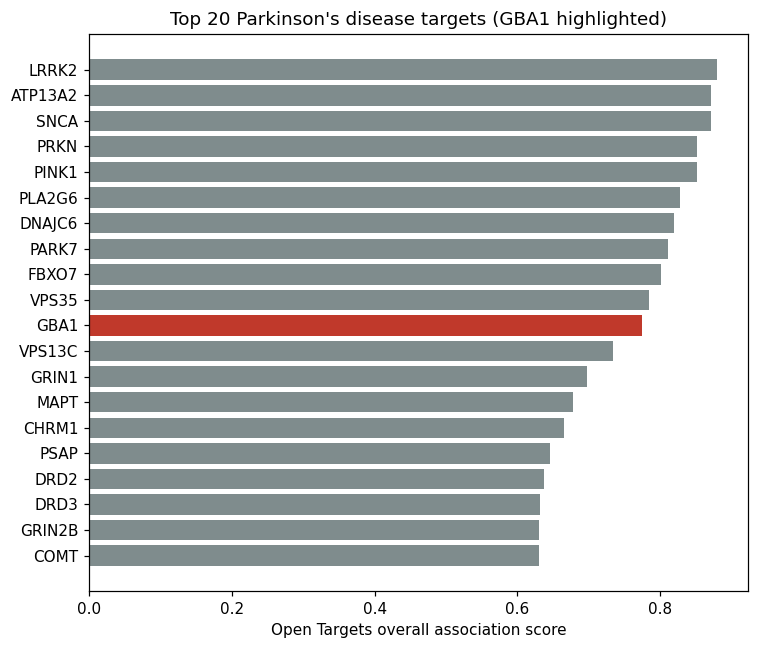

GBA1 overall rank: 11 of 1000


In [ ]:
top20 = ot.nlargest(20, "overall").iloc[::-1]
colours = ["#c0392b" if g == FOCUS_GENE else "#7f8c8d" for g in top20["gene"]]

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top20["gene"], top20["overall"], color=colours)
ax.set_xlabel("Open Targets overall association score")
ax.set_title("Top 20 Parkinson's disease targets (" + FOCUS_GENE + " highlighted)")
plt.tight_layout()
plt.savefig("fig1_top20.png")
plt.show()

rank = ot["overall"].rank(ascending=False).loc[ot["gene"] == FOCUS_GENE]
print(f"{FOCUS_GENE} overall rank: {int(rank.iloc[0]) if len(rank) else 'not found'} of {len(ot)}")

### Figure 2 — Genetic evidence vs literature attention
Targets in the **top-left** have strong genetic evidence but relatively little literature: candidate *under-studied* targets.

The thresholds below are a simple, transparent choice (genetic score in the top quartile, literature score below the median of genetically supported targets). Say this in your write-up.

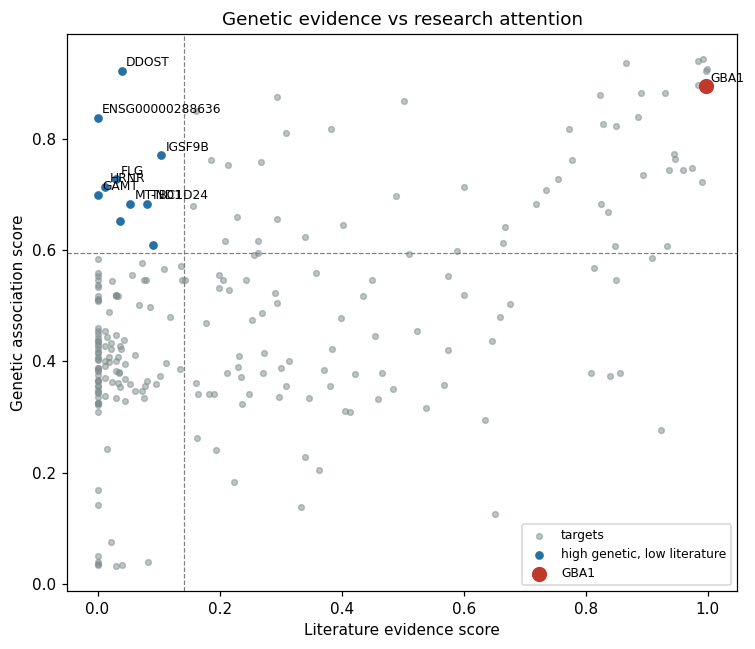

Spearman correlation (n=236): rho = 0.41, p = 5.9e-11


,gene,name,genetic_association,literature,overall
47,DDOST,dolichyl-diphosphooligosaccharide--protein gly...,0.922264,0.039347,0.561869
94,ENSG00000288636,novel protein,0.837788,0.000000,0.509317
139,IGSF9B,immunoglobulin superfamily member 9B,0.770475,0.104455,0.471571
216,FLG,filaggrin,0.727775,0.030397,0.443361
228,HRNR,hornerin,0.714107,0.012159,0.434497
238,GAMT,guanidinoacetate N-methyltransferase,0.699120,0.000000,0.425017
117,MT-ND1,mitochondrially encoded NADH:ubiquinone oxidor...,0.683922,0.053167,0.494775
247,TBC1D24,TBC1 domain family member 24,0.683922,0.080509,0.418225
268,SLC45A3,solute carrier family 45 member 3,0.652047,0.036307,0.397503
316,FAM47E,family with sequence similarity 47 member E,0.608838,0.090325,0.372877


In [ ]:
gen, lit = "genetic_association", "literature"
df = ot[(ot[gen] > 0)].copy()

gen_cut = df[gen].quantile(0.75)
lit_cut = df[lit].median()
df["understudied"] = (df[gen] >= gen_cut) & (df[lit] < lit_cut)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(df[lit], df[gen], s=14, alpha=0.5, color="#7f8c8d", label="targets")
u = df[df["understudied"]]
ax.scatter(u[lit], u[gen], s=22, color="#2471a3", label="high genetic, low literature")
f = df[df["gene"] == FOCUS_GENE]
ax.scatter(f[lit], f[gen], s=80, color="#c0392b", label=FOCUS_GENE, zorder=3)
for _, r in pd.concat([u.nlargest(8, gen), f]).iterrows():
    ax.annotate(r["gene"], (r[lit], r[gen]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.axhline(gen_cut, ls="--", lw=0.8, color="grey"); ax.axvline(lit_cut, ls="--", lw=0.8, color="grey")
ax.set_xlabel("Literature evidence score")
ax.set_ylabel("Genetic association score")
ax.set_title("Genetic evidence vs research attention")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("fig2_genetic_vs_literature.png")
plt.show()

rho, p = stats.spearmanr(df[gen], df[lit])
print(f"Spearman correlation (n={len(df)}): rho = {rho:.2f}, p = {p:.2g}")
u.sort_values(gen, ascending=False)[["gene", "name", gen, lit, "overall"]].head(15)

### Figure 3 — Manhattan-style plot of GWAS hits
Each point is a reported association. The dashed line is genome-wide significance (p < 5×10⁻⁸).

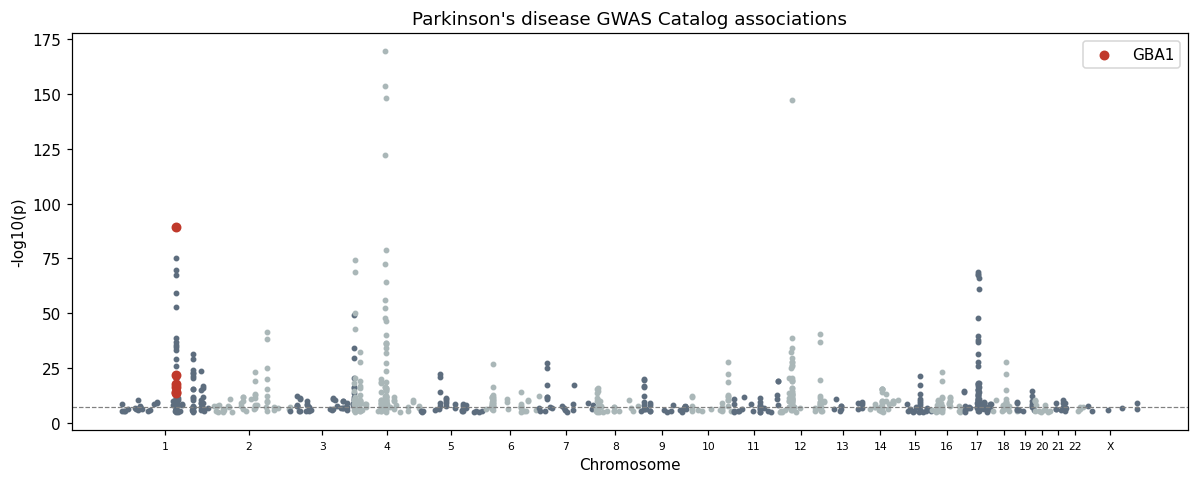

Genome-wide significant associations: 535
...mapped to GBA1: 6; median OR/beta = 1.63


,chr,pos,p,or,gene
14,1.0,155235843.0,3.000000e-90,4.1130,GBA1
680,1.0,155235843.0,2.000000e-22,0.7467,GBA1
141,1.0,155236376.0,1.000000e-18,0.4000,GBA1
56,1.0,155236376.0,5.000000e-17,1.6740,GBA1
658,1.0,155235252.0,1.000000e-14,1.9790,GBA1
677,1.0,155235878.0,2.000000e-14,1.5800,GBA1


In [ ]:
g = gwas.sort_values(["chr", "pos"]).copy()
offsets, ticks, start = {}, [], 0
for c in sorted(g["chr"].unique()):
    offsets[c] = start
    span = g.loc[g["chr"] == c, "pos"].max()
    ticks.append(start + span / 2)
    start += span
g["x"] = g["pos"] + g["chr"].map(offsets)
is_focus = g["gene"].str.contains(rf"(?<![\w-]){FOCUS_GENE}(?![\w-])", regex=True)

fig, ax = plt.subplots(figsize=(11, 4.5))
for i, c in enumerate(sorted(g["chr"].unique())):
    s = g[g["chr"] == c]
    ax.scatter(s["x"], s["neglog10p"], s=8, color=["#5d6d7e", "#aab7b8"][i % 2])
ax.scatter(g.loc[is_focus, "x"], g.loc[is_focus, "neglog10p"], s=30, color="#c0392b", label=FOCUS_GENE)
ax.axhline(-np.log10(5e-8), ls="--", color="grey", lw=0.8)
ax.set_xticks(ticks)
ax.set_xticklabels([("X" if int(c) == 23 else int(c)) for c in sorted(g["chr"].unique())], fontsize=7)
ax.set_xlabel("Chromosome"); ax.set_ylabel("-log10(p)")
ax.set_title("Parkinson's disease GWAS Catalog associations")
ax.legend()
plt.tight_layout()
plt.savefig("fig3_manhattan.png")
plt.show()

sig = g[g["p"] < 5e-8]
fs = sig[sig["gene"].str.contains(rf"(?<![\w-]){FOCUS_GENE}(?![\w-])", regex=True)]
print(f"Genome-wide significant associations: {len(sig)}")
print(f"...mapped to {FOCUS_GENE}: {len(fs)}; median OR/beta = {fs['or'].median():.2f}")
fs[["chr", "pos", "p", "or", "gene"]].sort_values("p").head(10)

Step 5 · Literature appraisal

Papers read:

Sidransky et al. (2009) Multicenter analysis of glucocerebrosidase mutations in Parkinson’s disease. NEJM 361:1651–61.
Mazzulli et al. (2011) Gaucher disease glucocerebrosidase and α-synuclein form a bidirectional pathogenic loop in synucleinopathies. Cell 146:37–52.
Nalls et al. (2019) Identification of novel risk loci, causal insights, and heritable risk for Parkinson’s disease: a meta-analysis of genome-wide association studies. Lancet Neurology 18:1091–102.

Mechanism:

GBA1 encodes glucocerebrosidase (GCase), a lysosomal enzyme that breaks down the lipid glucosylceramide. If a person carries a GBA1 variant, GCase activity drops and the lysosome becomes less able to break down proteins, including α-synuclein. α-synuclein then builds up, and glucosylceramide helps stabilise the toxic oligomer forms of it. α-synuclein also inhibits normal GCase, so the two form a positive feedback loop: less GCase leads to more α-synuclein, which leads to even less GCase (Mazzulli et al., 2011). This could explain how the disease becomes self-propagating. It also suggests that boosting GCase activity, or improving its delivery to the lysosome, could be a therapy, which is the idea behind current GBA1-targeted programmes.

Critical appraisal of one study: Sidransky et al. (2009)

Design: an international case–control study pooling data from 16 centres across the Americas, Europe, Israel and Asia. Each centre genotyped the same standard DNA panel so the results could be compared.
Sample size: 5,691 Parkinson’s patients and 4,898 controls, which is large enough to detect a relatively rare risk variant.
Key result: carrying any GBA1 mutation was associated with an odds ratio of 5.43 for Parkinson’s. Carriers had an earlier onset, were more likely to have affected relatives, and more often had atypical features.
Population/ancestry: the results differed strongly by ancestry. Among Ashkenazi Jewish participants, 15% of patients and 3% of controls carried one of the two common mutations (N370S or L444P). In non-Ashkenazi participants the figures were about 3% and under 1%. Pooling such different populations makes the single odds ratio harder to interpret.
Limitations: most centres screened only the two common mutations. Where the gene was fully sequenced in non-Ashkenazi patients, 7% carried a mutation, so screening only for the common variants probably missed around half of carriers and underestimated how common GBA1 variants are. A case–control design shows association, not causation, and controls were recruited differently at different centres.
Overall: strong evidence that GBA1 is a major genetic risk factor for Parkinson’s. The large GWAS by Nalls et al. (2019), with 37,688 cases and about 1.4 million controls, also found a signal at the GBA1 locus, but that study included only people of European ancestry.

## Step 6 · Interpretation and limitations
Step 6 · Interpretation and limitations

What I found

GBA1 ranked 11 out of 1000 Parkinsons targets by overall Open Targets score. This fits its known status as one of the strongest genetic risk factors.
Targets with a high genetic association score but low literature score included DDOST, ENSG00000288636, IGSF9B. These could be under-explored targets worth investigating, although some may have low literature scores just because they are newly identified.
The Spearman correlation between genetic and literature scores was rho = 0.41, p = 5.9e-11, . This suggests well-supported genes do tend to be studied more,  but with exceptions.

Limitations

GWAS associations show correlation, not causation, and the gene mapped to a variant is not always the causal gene.
Most GWAS cohorts, including the largest Parkinson’s meta-analysis (Nalls et al., 2019), are of European ancestry, so the findings may not apply equally to other populations.
Open Targets literature scores come from text-mining and are an imperfect measure of research attention.
My thresholds for “under-studied” (top quarter of genetic score, below-median literature score) were a simple choice, and different cut-offs would change the list.
I compared targets for one disease at a single point in time. Open Targets updates its data regularly, so scores may change.

## AI log (fill in as you go)
| Step | What I asked the AI | What I checked / changed |
|---|---|---|
| 2 | *e.g. "Explain each column in this table"* | *Checked SNCA and LRRK2 scores against the website: matched* |
| | | |